In [51]:
import os
import numpy as np
import pandas as pd

In [52]:
# Create dataset folder
os.makedirs("dataset", exist_ok=True)

np.random.seed(42)

n = 1200

age = np.random.randint(18, 90, n)

gender = np.random.choice(
    ["Male", "Female"], n
)

admission_type = np.random.choice(
    ["Emergency", "Elective", "Urgent"],
    n,
    p=[0.45, 0.30, 0.25]
)

previous_visits = np.random.poisson(1.2, n)
previous_visits = np.clip(previous_visits, 0, 10)

length_of_stay = np.random.randint(1, 22, n)

num_procedures = np.random.randint(0, 7, n)

num_medications = np.random.randint(1, 18, n)

chronic_conditions = np.random.randint(0, 6, n)

In [53]:
# Generate a simulated readmission probability
z = (
    -3.0
    + 0.025 * (age - 50)
    + 0.22 * previous_visits
    + 0.055 * length_of_stay
    + 0.18 * chronic_conditions
    + 0.08 * num_medications
    + np.where(admission_type == "Emergency", 0.55, 0)
    + np.where(admission_type == "Urgent", 0.25, 0)
)

probability = 1 / (1 + np.exp(-z))

readmitted = np.random.binomial(1, probability)

data = pd.DataFrame({
    "age": age,
    "gender": gender,
    "admission_type": admission_type,
    "previous_visits": previous_visits,
    "length_of_stay": length_of_stay,
    "num_procedures": num_procedures,
    "num_medications": num_medications,
    "chronic_conditions": chronic_conditions,
    "readmitted": readmitted
})

data.to_csv(
    "dataset/hospital_dataset.csv",
    index=False
)

print("Dataset generated successfully!")
print(data.head())
print("\nDataset shape:", data.shape)
print("\nReadmission distribution:")
print(data["readmitted"].value_counts())

Dataset generated successfully!
   age  gender admission_type  previous_visits  length_of_stay  \
0   69  Female         Urgent                1              14   
1   32    Male      Emergency                2              14   
2   89    Male         Urgent                1              13   
3   78  Female       Elective                1               6   
4   38  Female       Elective                3              17   

   num_procedures  num_medications  chronic_conditions  readmitted  
0               4               14                   3           0  
1               6               14                   4           1  
2               4                1                   1           0  
3               1               16                   4           1  
4               2               15                   1           0  

Dataset shape: (1200, 9)

Readmission distribution:
readmitted
0    727
1    473
Name: count, dtype: int64


In [54]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [55]:
def load_dataset():

    data = pd.read_csv(
        "dataset/hospital_dataset.csv"
    )

    return data


def prepare_preprocessor():

    numerical_features = [
        "age",
        "previous_visits",
        "length_of_stay",
        "num_procedures",
        "num_medications",
        "chronic_conditions"
    ]

    categorical_features = [
        "gender",
        "admission_type"
    ]

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor

In [56]:
import os
import joblib
import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score






In [57]:
def load_dataset(file_path):
    df = pd.read_csv(file_path)
    return df

In [58]:
# Create model folder
os.makedirs("model", exist_ok=True)

In [59]:
# Separate features and target
X = data.drop("readmitted", axis=1)
y = data["readmitted"]

In [60]:
# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [61]:
# Preprocessing
preprocessor = prepare_preprocessor()

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


In [62]:
# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    "model/preprocessor.pkl"
)

# Build ANN model
model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(X_train.shape[1],)
    ),

    tf.keras.layers.Dense(
        32,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Dense(
        16,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

In [63]:
# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [64]:
# Early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train model
history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=35,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5794 - auc: 0.5281 - loss: 0.6894 - val_accuracy: 0.5938 - val_auc: 0.4891 - val_loss: 0.6791
Epoch 2/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6146 - auc: 0.5898 - loss: 0.6637 - val_accuracy: 0.5938 - val_auc: 0.5558 - val_loss: 0.6609
Epoch 3/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6302 - auc: 0.6190 - loss: 0.6519 - val_accuracy: 0.6198 - val_auc: 0.6068 - val_loss: 0.6467
Epoch 4/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6471 - auc: 0.6675 - loss: 0.6297 - val_accuracy: 0.5990 - val_auc: 0.6380 - val_loss: 0.6385
Epoch 5/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6497 - auc: 0.6665 - loss: 0.6322 - val_accuracy: 0.6250 - val_auc: 0.6520 - val_loss: 0.6317
Epoch 6/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6706 - auc: 0.6961 - loss: 0.6147 - val_accuracy: 0.6354 - val_auc: 0.6632 - val_loss: 0.6267
Epoch 7/35
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step -

In [65]:
# Evaluate on test dataset
loss, accuracy, auc = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nMODEL TRAINING COMPLETED")
print("------------------------")
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test AUC:", auc)


MODEL TRAINING COMPLETED
------------------------
Test Loss: 0.5837268829345703
Test Accuracy: 0.6875
Test AUC: 0.732704222202301


In [66]:
# Save trained ANN
model.save("model/hospital_ann.keras")

print("\nModel saved successfully!")


Model saved successfully!


In [67]:
pip install pandas numpy scikit-learn joblib

In [68]:
import joblib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

In [70]:
# Load original dataset
data = load_dataset("dataset/hospital_dataset.csv")


In [71]:
X = data.drop("readmitted", axis=1)
y = data["readmitted"]



In [72]:
# Recreate the same split used during training
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [73]:
# Load saved preprocessing pipeline
preprocessor = joblib.load(
    "model/preprocessor.pkl"
)

X_test = preprocessor.transform(X_test)


In [74]:
# Load trained model
model = tf.keras.models.load_model(
    "model/hospital_ann.keras"
)


In [75]:
# Predictions
probabilities = model.predict(
    X_test,
    verbose=0
).ravel()

predictions = (probabilities >= 0.5).astype(int)

In [76]:
# Calculate evaluation metrics
print("\nMODEL EVALUATION RESULTS")
print("------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, predictions)
)

print(
    "Precision:",
    precision_score(
        y_test, predictions, zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test, predictions, zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test, predictions, zero_division=0
    )
)

print(
    "ROC AUC:",
    roc_auc_score(y_test, probabilities)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)



MODEL EVALUATION RESULTS
------------------------
Accuracy: 0.6875
Precision: 0.6282051282051282
Recall: 0.5157894736842106
F1 Score: 0.5664739884393064
ROC AUC: 0.7328493647912885

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.80      0.76       145
           1       0.63      0.52      0.57        95

    accuracy                           0.69       240
   macro avg       0.67      0.66      0.66       240
weighted avg       0.68      0.69      0.68       240



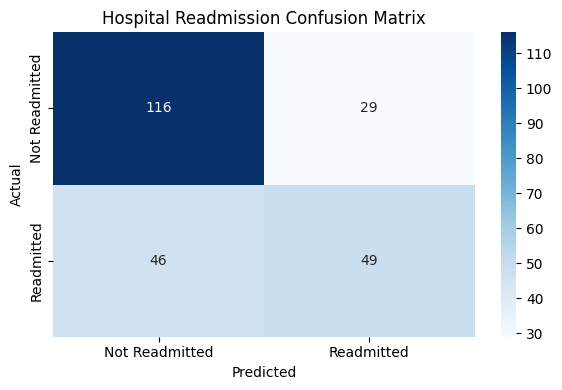

In [77]:
# Confusion matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Readmitted", "Readmitted"],
    yticklabels=["Not Readmitted", "Readmitted"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Hospital Readmission Confusion Matrix")

plt.tight_layout()
plt.savefig("model/confusion_matrix.png")
plt.show()


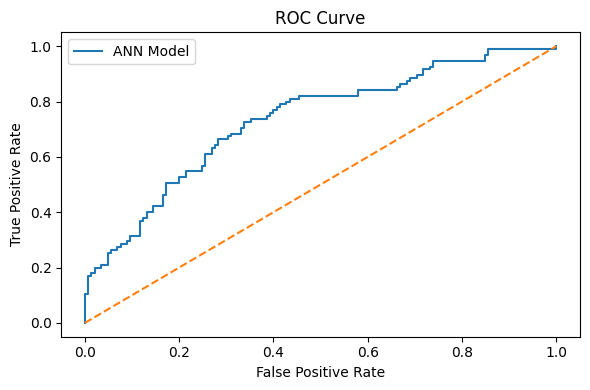

In [78]:
# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    probabilities
)

plt.figure(figsize=(6, 4))

plt.plot(
    fpr,
    tpr,
    label="ANN Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.tight_layout()
plt.savefig("model/roc_curve.png")
plt.show()


In [79]:
import pandas as pd
import joblib
import tensorflow as tf


In [81]:
# Load trained model
model = tf.keras.models.load_model(
    "model/hospital_ann.keras"
)

# Load preprocessing pipeline
preprocessor = joblib.load(
    "model/preprocessor.pkl"
)

print("HOSPITAL READMISSION PREDICTION")
print("--------------------------------")

# Get patient information
age = int(input("Enter patient age: "))

gender = input(
    "Enter gender (Male/Female): "
).strip().capitalize()

admission_type = input(
    "Admission type (Emergency/Elective/Urgent): "
).strip().capitalize()

previous_visits = int(
    input("Previous hospital visits: ")
)

length_of_stay = int(
    input("Length of stay in days: ")
)

num_procedures = int(
    input("Number of procedures: ")
)

num_medications = int(
    input("Number of medications: ")
)

chronic_conditions = int(
    input("Number of chronic conditions: ")
)

# Create patient DataFrame
patient = pd.DataFrame([{
    "age": age,
    "gender": gender,
    "admission_type": admission_type,
    "previous_visits": previous_visits,
    "length_of_stay": length_of_stay,
    "num_procedures": num_procedures,
    "num_medications": num_medications,
    "chronic_conditions": chronic_conditions
}])

HOSPITAL READMISSION PREDICTION
--------------------------------
Enter patient age: 69
Enter gender (Male/Female): Female
Admission type (Emergency/Elective/Urgent): Urgent
Previous hospital visits: 1
Length of stay in days: 14
Number of procedures: 4
Number of medications: 14
Number of chronic conditions: 3


In [82]:
# Preprocess patient data
patient_processed = preprocessor.transform(
    patient
)

In [83]:
# Predict probability
prediction = model.predict(
    patient_processed,
    verbose=0
)[0][0]

print("\nPREDICTION RESULT")
print("-----------------")

print(
    "Estimated readmission probability:",
    round(float(prediction) * 100, 2),
    "%"
)

if prediction >= 0.5:
    print("Model classification: Higher predicted risk")
else:
    print("Model classification: Lower predicted risk")

print(
    "\nNote: Educational prediction only. "
    "Not suitable for clinical decisions."
)



PREDICTION RESULT
-----------------
Estimated readmission probability: 54.95 %
Model classification: Higher predicted risk

Note: Educational prediction only. Not suitable for clinical decisions.
